# Absolute stability, A-stability and stiffness

**Source:** CompSci §4.4.1, pp. 27–30 · [Source map](../docs/SOURCES.md) · [Course index](../README.md)

For $y'=\lambda y$ one step multiplies by $R(z)$, $z=h\lambda$. Forward Euler has $R=1+z$; backward Euler $R=1/(1-z)$; trapezoidal $R=(1+z/2)/(1-z/2)$. Absolute stability requires $|R|\le 1$, while strict inequality gives decay. A-stability contains the entire left half-plane. L-stability additionally damps very fast modes as $|z|\to\infty$ in that half-plane. Backward Euler has both properties; trapezoidal tends to $-1$ on the negative real axis.

For independent decay rates 1 and 100, the explicit stability bound is $h<0.02$ even if only the slow component needs resolving. For nonlinear problems the local Jacobian provides a diagnostic, not a complete stiffness criterion.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.22,
                     "axes.spines.top": False, "axes.spines.right": False})
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "01_Foundations").is_dir() and (p / "requirements.txt").is_file())
out = root / "assets" / "figures"
out.mkdir(parents=True, exist_ok=True)

def show(fig, name):
    fig.tight_layout()
    fig.savefig(out / (name + ".png"), dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

Matplotlib is building the font cache; this may take a moment.


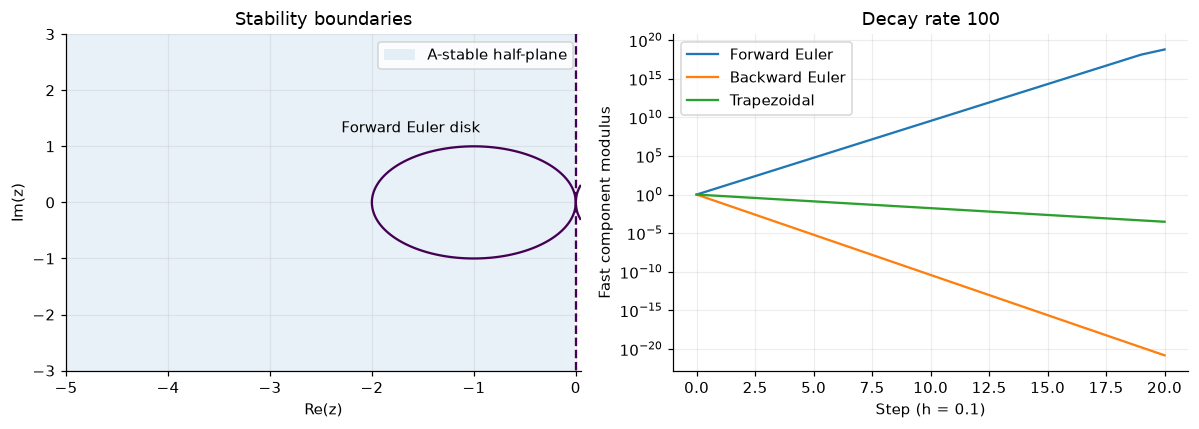

In [2]:
methods={"Forward Euler":lambda z:1+z,"Backward Euler":lambda z:1/(1-z),
         "Trapezoidal":lambda z:(1+z/2)/(1-z/2)}
a=np.linspace(-5,.05,450); b=np.linspace(-3,3,400); z=a[None,:]+1j*b[:,None]
fig,ax=plt.subplots(1,2,figsize=(11,4))
for name,R in methods.items():
    ax[0].contour(a,b,abs(R(z)),levels=[1],linestyles="--" if name=="Trapezoidal" else "-")
    n=np.arange(21)
    ax[1].semilogy(n,np.maximum(abs(R(-10)**n),1e-24),label=name)
ax[0].fill_between(a,-3,3,where=a<=0,alpha=.10,label="A-stable half-plane")
ax[0].text(-2.3,1.25,"Forward Euler disk")
ax[0].set(xlabel="Re(z)",ylabel="Im(z)",title="Stability boundaries"); ax[0].legend()
ax[1].set(xlabel="Step (h = 0.1)",ylabel="Fast component modulus",title="Decay rate 100"); ax[1].legend()
show(fig,"04-stability")
assert abs(methods["Forward Euler"](-10))>1
assert abs(methods["Backward Euler"](-10000))<1e-3
assert abs(methods["Trapezoidal"](-10000))>.999

## Worked exercise

**Why can a stable solution still be inaccurate?** Trapezoidal at $z=-10$ gives $-2/3$, versus exact multiplication by $e^{-10}$. The step stays bounded but creates an alternating residual. Time resolution must still be chosen for accuracy.

## Additional experiment

Stiff decay with both a slow and a fast component.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True})
rng = np.random.default_rng(42)

In [ ]:
rates=np.array([1.,100.]);h=.05;t=np.arange(101)*h
for name,R in [("Explicit",1-h*rates),("Implicit",1/(1+h*rates)),("Trapezoidal",(1-h*rates/2)/(1+h*rates/2))]:
 values=R[None,:]**np.arange(101)[:,None]
 plt.semilogy(t,np.maximum(abs(values[:,1]),1e-30),label=name)
plt.xlabel("time");plt.ylabel("absolute fast component");plt.legend();plt.show()
assert abs(1-h*100)>1 and abs(1/(1+h*100))<1
xx,yy=np.meshgrid(np.linspace(-4,1,250),np.linspace(-3,3,250));z=xx+1j*yy
plt.contourf(xx,yy,abs(1+z),levels=[0,1],alpha=.5);plt.xlabel("Re(h lambda)");plt.ylabel("Im(h lambda)");plt.title("Explicit Euler stability region");plt.show()

## Further practice

Compare backward Euler and trapezoidal decay when h*100=20. Why is A-stability insufficient to guarantee strong damping?

Record: prediction → observation → explanation. A successful assertion checks this example; it is not a general proof.